# 02 · Modelado

**Objetivo:** entrenar un primer modelo KNN (baseline) para predecir el precio de alquiler por m²

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

- cargamos el dataset limpio

In [2]:
apartments = pd.read_csv("../data/clean/apartments_clean.csv")
apartments.shape

(9878, 40)

- elijo los features y el target

In [3]:
features = apartments.drop(columns=["price", "price_per_m2", "cityname", "state"])
target = apartments["price_per_m2"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.20, random_state=0)

In [5]:
X_train.head()

,bathrooms,bedrooms,has_photo,latitude,longitude,cats_allowed,dogs_allowed,AC,Alarm,Basketball,...,Pool,Refrigerator,Storage,TV,Tennis,View,Washer Dryer,Wood Floors,amenities_count,area_m2
6464,1.0,1.0,1,35.4710,-97.5299,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,89.372686
2571,1.0,1.0,1,29.7714,-95.4343,1,1,0,0,0,...,1,1,0,0,0,0,0,0,7,60.386950
5136,1.0,1.0,1,40.2967,-74.6137,0,0,0,0,0,...,1,0,0,0,1,0,0,0,4,76.644975
3444,1.0,1.0,1,42.0259,-93.6516,0,0,0,0,0,...,0,0,0,0,0,0,0,0,4,65.217906
1957,1.0,2.0,1,32.7407,-97.3394,1,1,0,0,0,...,1,1,1,0,0,0,0,0,9,56.020509


In [6]:
y_train.head()

6464    12.252065
2571    11.426310
5136    20.705858
3444     9.199927
1957    19.189401
Name: price_per_m2, dtype: float64

- Empezamos a entrenar el modelo con Knn

In [7]:
knn = KNeighborsRegressor()
knn

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None


In [8]:
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [9]:
pred = knn.predict(X_test)
pred

array([18.25756477, 11.58202908, 11.7521814 , ..., 15.80552506,
       22.64246027, 20.71971719], shape=(1976,))

In [10]:
y_test.values

array([18.2683347 , 13.49551236, 14.18390442, ..., 15.4738985 ,
       19.91324284, 13.14439626], shape=(1976,))

- Evaluación:

In [11]:
knn.score(X_test, y_test) 

0.5905488319492813

- Interpretación: R² = 0,59

El modelo explica el 59% de la variación del precio por m². Para un baseline sin escalar, sin ubicación por ciudad y sin ajustar nada, es un buen punto de partida

In [12]:
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 4.381551494243131
RMSE: 6.756269721898556


**Observación:** el modelo base explica el 59% de la variación del precio por m², con un error medio de 4,36 $/m². El RMSE, notablemente superior al MAE, indica la presencia de algunos errores grandes, probablemente asociados a valores extremos de precio por m². Este resultado servirá como referencia para medir las mejoras.

### Feature Engineering

Se aplicaran dos técnicas de escalado ('MinMaxScaler' y 'StandardScaler') y se comparan sus resultados para elegir la más adecuada.

- MinMaxScaler (Normalización):
    KNN es un algoritmo basado en distancias, por lo que las variables con valores grandes (como 'area_m2') dominan sobre las demás. Se aplica 'MinMaxScaler' para llevar todas las variables al rango 0-1.

In [13]:
normalizer = MinMaxScaler()
normalizer.fit(X_train)

X_train_norm = normalizer.transform(X_train)
X_test_norm = normalizer.transform(X_test)

X_train_norm = pd.DataFrame(X_train_norm, columns=X_train.columns)
X_test_norm = pd.DataFrame(X_test_norm, columns=X_test.columns)
X_train_norm.head()

,bathrooms,bedrooms,has_photo,latitude,longitude,cats_allowed,dogs_allowed,AC,Alarm,Basketball,...,Pool,Refrigerator,Storage,TV,Tennis,View,Washer Dryer,Wood Floors,amenities_count,area_m2
0,0.0,0.125,1.0,0.351441,0.689952,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.076264
1,0.0,0.125,1.0,0.209936,0.713853,1.0,1.0,0.0,0.0,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.388889,0.048435
2,0.0,0.125,1.0,0.471249,0.951325,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.222222,0.064044
3,0.0,0.125,1.0,0.514180,0.734186,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.222222,0.053073
4,0.0,0.250,1.0,0.283655,0.692124,1.0,1.0,0.0,0.0,0.0,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.500000,0.044242


In [14]:
knn = KNeighborsRegressor()
knn.fit(X_train_norm, y_train)
pred_norm = knn.predict(X_test_norm)

r2 = knn.score(X_test_norm, y_test)
mae = mean_absolute_error(y_test, pred_norm)
rmse = np.sqrt(mean_squared_error(y_test, pred_norm))

print("R²:", r2)
print("MAE:", mae)
print("RMSE:", rmse)

R²: 0.4458808196157493
MAE: 5.173459572049663
RMSE: 7.859727939670124


- StandardScaler (Estandarizar):
    Como alternativa, se aplica StandardScaler', que transforma cada variable para que tenga media 0 y desviación típica 1. Es menos sensible a los valores extremos que 'MinMaxScaler'.

In [15]:
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)
X_train_scaled.head()

,bathrooms,bedrooms,has_photo,latitude,longitude,cats_allowed,dogs_allowed,AC,Alarm,Basketball,...,Pool,Refrigerator,Storage,TV,Tennis,View,Washer Dryer,Wood Floors,amenities_count,area_m2
0,-0.616109,-0.792567,0.139576,-0.405759,-0.185948,-1.147738,-1.063517,-0.269483,-0.049094,-0.185549,...,-0.692058,-0.681283,-0.429363,-0.144216,-0.221953,-0.119362,-0.34695,-0.193785,-0.911786,0.036101
1,-0.616109,-0.792567,0.139576,-1.441992,-0.053307,0.871279,0.940277,-0.269483,-0.049094,-0.185549,...,1.444965,1.467818,-0.429363,-0.144216,-0.221953,-0.119362,-0.34695,-0.193785,1.123670,-0.553768
2,-0.616109,-0.792567,0.139576,0.471592,1.264532,-1.147738,-1.063517,-0.269483,-0.049094,-0.185549,...,1.444965,-0.681283,-0.429363,-0.144216,4.505462,-0.119362,-0.34695,-0.193785,0.251332,-0.222912
3,-0.616109,-0.792567,0.139576,0.785974,0.059529,-1.147738,-1.063517,-0.269483,-0.049094,-0.185549,...,-0.692058,-0.681283,-0.429363,-0.144216,-0.221953,-0.119362,-0.34695,-0.193785,0.251332,-0.455456
4,-0.616109,0.275270,0.139576,-0.902150,-0.173890,0.871279,0.940277,-0.269483,-0.049094,-0.185549,...,1.444965,1.467818,2.329032,-0.144216,-0.221953,-0.119362,-0.34695,-0.193785,1.705229,-0.642626


In [16]:
knn = KNeighborsRegressor()
knn.fit(X_train_scaled, y_train)
pred_scaled = knn.predict(X_test_scaled)

r2 = knn.score(X_test_scaled, y_test)
mae = mean_absolute_error(y_test, pred_scaled)
rmse = np.sqrt(mean_squared_error(y_test, pred_scaled))

print("R²:", r2)
print("MAE:", mae)
print("RMSE:", rmse)

R²: 0.4812828148488796
MAE: 5.064229311329869
RMSE: 7.6045100828984165


**Observación:** ambos escalados empeoran el resultado respecto al baseline (R² de 0,59 a 0,48 con StandardScaler). Sin escalar, el modelo se apoyaba en 'area_m2' y las coordenadas, que probablemente son las variables más relevantes; al escalar, las 28 variables de servicios adquieren el mismo peso y podrían estar añadiendo ruido. Se elige 'StandardScaler' por obtener mejores métricas, y se aplicará selección de variables para comprobar esta hipótesis.

### 2. Selección de variables
Se analiza la correlación de cada variable con el target para identificar cuáles aportan información y cuáles podrían estar añadiendo ruido.

In [17]:
correlations = X_train.corrwith(y_train).abs().sort_values(ascending=False)
correlations

area_m2               0.323381
bedrooms              0.264878
longitude             0.244601
bathrooms             0.211916
Elevator              0.126361
Playground            0.103818
dogs_allowed          0.076478
Fireplace             0.067657
Garbage Disposal      0.065015
cats_allowed          0.061347
Tennis                0.059500
Clubhouse             0.051558
Washer Dryer          0.047254
latitude              0.047070
Patio/Deck            0.045494
View                  0.044772
Wood Floors           0.042421
Basketball            0.040308
amenities_count       0.040133
Dishwasher            0.031441
Doorman               0.026585
Hot Tub               0.026216
Pool                  0.023495
Gym                   0.019661
AC                    0.018519
Internet Access       0.018161
Luxury                0.017750
Parking               0.015560
Gated                 0.011446
Cable or Satellite    0.011401
Storage               0.010998
has_photo             0.008606
Refriger

- El heatmap se limita a las variables principales, excluyendo a las columnas de los 27 servicios individuales, por legibilidad y porque su correlación con el target es muy baja (< 0,13), quedando representados por 'amenities_count'.

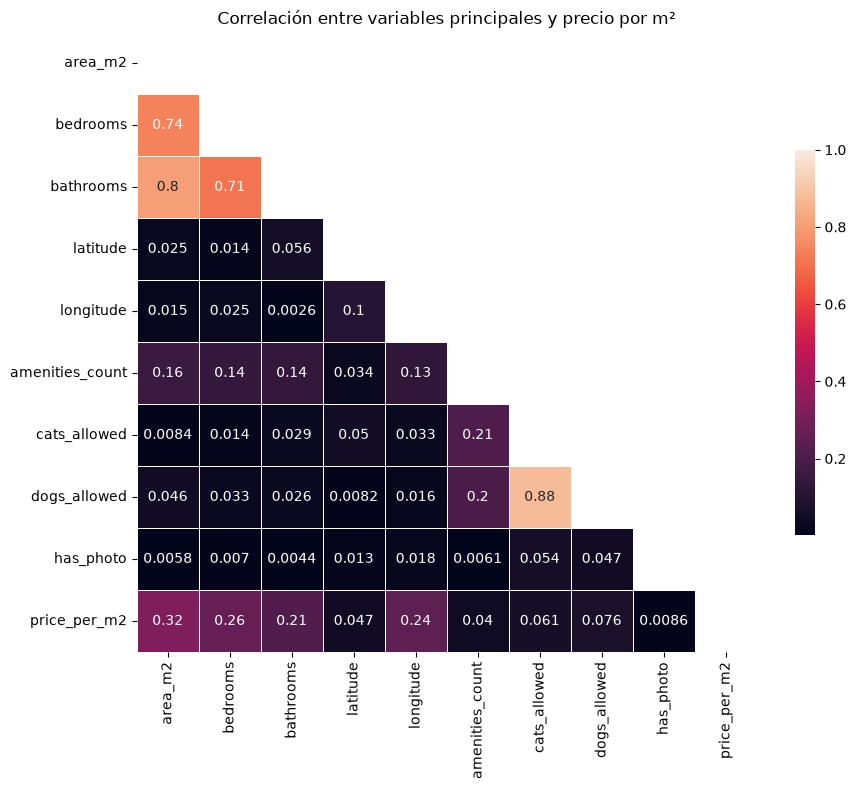

In [18]:
main_features = ["area_m2", "bedrooms", "bathrooms", "latitude", "longitude",
                 "amenities_count", "cats_allowed", "dogs_allowed", "has_photo"]

corr_data = X_train[main_features].copy()
corr_data["price_per_m2"] = y_train
corr = np.abs(corr_data.corr())

mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True

f, ax = plt.subplots(figsize=(10, 10))
cmap = sns.diverging_palette(220, 10, as_cmap=True)
sns.heatmap(corr, mask=mask, vmax=1, square=True, linewidths=.5,
            cbar_kws={"shrink": .5}, annot=corr)
plt.title("Correlación entre variables principales y precio por m²")
plt.show()

se eliminan 'bathrooms' (muy correlacionada con 'area_m2') y 'cats_allowed' (muy correlacionada con 'dogs_allowed'), así como 'has_photo', 'amenities_count' y los servicios individuales por su baja correlación con el target. 'latitude' se conserva porque, junto con 'longitude', define la ubicación.

In [19]:
selected_features = ["area_m2", "bedrooms", "latitude", "longitude", "dogs_allowed"]
X_train_reduced = X_train_scaled[selected_features]
X_test_reduced = X_test_scaled[selected_features]

knn = KNeighborsRegressor(n_neighbors=10)
knn.fit(X_train_reduced, y_train)
pred_reduced = knn.predict(X_test_reduced)

In [20]:
r2 = knn.score(X_test_reduced, y_test)
mae = mean_absolute_error(y_test, pred_reduced)
rmse = np.sqrt(mean_squared_error(y_test, pred_reduced))

print("R²:", r2)
print("MAE:", mae)
print("RMSE:", rmse)

R²: 0.624459837663891
MAE: 4.218199677154467
RMSE: 6.470444503918136


la selección por correlación empeora claramente el modelo (R² = 0,13). La correlación solo mide relaciones lineales de cada variable por separado, mientras que KNN aprovecha combinaciones de variables (por ejemplo, el conjunto de servicios describe el tipo de edificio). Se descarta esta selección y se prueban alternativas.

- EXPERIMENTOS  Y COMBINACIONES

In [23]:
def evaluate_knn(X_tr, X_te):
    """Entrena un KNN con parámetros por defecto y devuelve R², MAE y RMSE sobre el test."""
    knn = KNeighborsRegressor()
    knn.fit(X_tr, y_train)
    pred = knn.predict(X_te)

    r2 = knn.score(X_te, y_test)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    return round(r2, 3), round(mae, 2), round(float(rmse), 2)

In [24]:
drop_redundant = ["bathrooms", "cats_allowed", "has_photo", "amenities_count"]

print("Escalado, todas las features:      ", evaluate_knn(X_train_scaled, X_test_scaled))
print("Escalado, sin redundantes:          ", evaluate_knn(X_train_scaled.drop(columns=drop_redundant), X_test_scaled.drop(columns=drop_redundant)))
print("Sin escalar, 5 features:            ", evaluate_knn(X_train[selected_features], X_test[selected_features]))
print("Sin escalar, todas las features:    ", evaluate_knn(X_train, X_test))

Escalado, todas las features:       (0.481, 5.06, 7.6)
Escalado, sin redundantes:           (0.511, 4.92, 7.38)
Sin escalar, 5 features:             (0.601, 4.3, 6.67)
Sin escalar, todas las features:     (0.591, 4.38, 6.76)


In [ ]:
def evaluate_model(model, X_tr, X_te):
    """Entrena el modelo recibido y devuelve R², MAE y RMSE sobre el test."""
    model.fit(X_tr, y_train)
    pred = model.predict(X_te)

    r2 = model.score(X_te, y_test)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    return round(r2, 3), round(mae, 2), round(rmse, 2)

In [ ]:
drop_redundant = ["bathrooms", "cats_allowed", "has_photo", "amenities_count"]
X_train_scaled_red = X_train_scaled.drop(columns=drop_redundant)
X_test_scaled_red = X_test_scaled.drop(columns=drop_redundant)

print("KNN, sin escalar, todas:        ", evaluate_model(KNeighborsRegressor(), X_train, X_test))
print("KNN, escalado, todas:           ", evaluate_model(KNeighborsRegressor(), X_train_scaled, X_test_scaled))
print("KNN, escalado, sin redundantes: ", evaluate_model(KNeighborsRegressor(), X_train_scaled_red, X_test_scaled_red))
print("KNN, sin escalar, 5 features:   ", evaluate_model(KNeighborsRegressor(), X_train[selected_features], X_test[selected_features]))
print("Regresión lineal, todas:        ", evaluate_model(LinearRegression(), X_train, X_test))
print("Árbol de decisión, todas:       ", evaluate_model(DecisionTreeRegressor(random_state=42), X_train, X_test))